## Auto-encodeurs

L'objectif de ce BE est de manipuler des auto-encodeurs sur un exemple simple : la base de données MNIST. L'idée est de pouvoir visualiser les concepts vus en cours, et notamment d'illustrer la notion d'espace latent.

Les images MNIST sont des images en niveaux de gris, de taille 28x28 pixels, représentant des chiffres manuscrits de 0 à 9.

![mnist](http://i.ytimg.com/vi/0QI3xgXuB-Q/hqdefault.jpg)

Pour démarrer, nous vous fournissons un code permettant de créer un premier auto-encodeur simple, de charger les données MNIST  et d'entraîner cet auto-encodeur. **L'autoencodeur n'est pas convolutif !** (libre à vous de le transformer pour qu'il le soit, plus tard dans le BE)

L'auto-encodeur implémenté ci-dessous compte 2 couches pour l'encodeur et deux couches pour le décodeur.


<img src="https://drive.google.com/uc?id=16OQjf9cX3dBS8brwxTe7kKed51spclLC" width=400>



On définit 3 modèles : l'encodeur, le décodeur, et l'auto-encodeur qui consiste en une concaténation des deux précédents.


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil utilisé :", device)

# Cet encodeur basique est constitué de 2 couches complètement connectées
class Encoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, latent_dim)
        )

    def forward(self, x):
        return self.network(x)

# Idem pour le décodeur
class Decoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 784)
        )

    def forward(self, z):
        return self.network(z)

# L'auto-encodeur est la concaténation des deux modèles encodeur et décodeur
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.encoder = Encoder(latent_dim)
        self.decoder = Decoder(latent_dim)

    def forward(self, x):
        return self.decoder(self.encoder(x))

# Dimension de l'espace latent : PARAMETRE A TESTER !!
latent_dim = 32
encoder = Encoder(latent_dim).to(device)
decoder = Decoder(latent_dim).to(device)
autoencoder = Autoencoder(latent_dim).to(device)

On définit le chargement des données MNIST. Dans un premier temps notre auto-encodeur n'est pas convolutif : on vectorise donc les images MNIST pour les rendre traitables par des couches complètement connectées.

In [ ]:
from torchvision.datasets import MNIST
from torchvision import transforms

# Chargement de MNIST et normalisation des valeurs de niveau de gris entre 0 et 1
transform = transforms.ToTensor()
train_dataset = MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = MNIST(root="./data", train=False, download=True, transform=transform)

# Les images sont vectorisées en dimension 784 pour l'auto-encodeur dense
x_train = train_dataset.data.float().div(255.).view(-1, 784)
x_test = test_dataset.data.float().div(255.).view(-1, 784)

train_loader = DataLoader(TensorDataset(x_train, x_train), batch_size=128, shuffle=True)
test_loader = DataLoader(TensorDataset(x_test, x_test), batch_size=128, shuffle=False)


On optimisera le modèle en minimisant l'erreur de reconstruction, ce que l'on fait classiquement en utilisant une erreur quadratique moyenne comme fonction de coût.

In [ ]:
# Entraînement de l'auto-encodeur. Le jeu de test sert ici à suivre
# l'erreur de reconstruction sur des données non utilisées pour l'entraînement.
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(autoencoder.parameters())

epochs = 50
for epoch in range(epochs):
    autoencoder.train()
    train_loss = 0.0
    for images, targets in train_loader:
        images, targets = images.to(device), targets.to(device)
        optimizer.zero_grad()
        reconstructions = autoencoder(images)
        loss = criterion(reconstructions, targets)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * images.size(0)

    autoencoder.eval()
    test_loss = 0.0
    with torch.no_grad():
        for images, targets in test_loader:
            images, targets = images.to(device), targets.to(device)
            test_loss += criterion(autoencoder(images), targets).item() * images.size(0)

    print(f"Époque {epoch+1:02d}/{epochs} - "
          f"train: {train_loss/len(train_dataset):.5f} - "
          f"test: {test_loss/len(test_dataset):.5f}")

Le code suivant affiche des exemples d'images de la base de test (1e ligne) et de leur reconstruction (2e ligne).

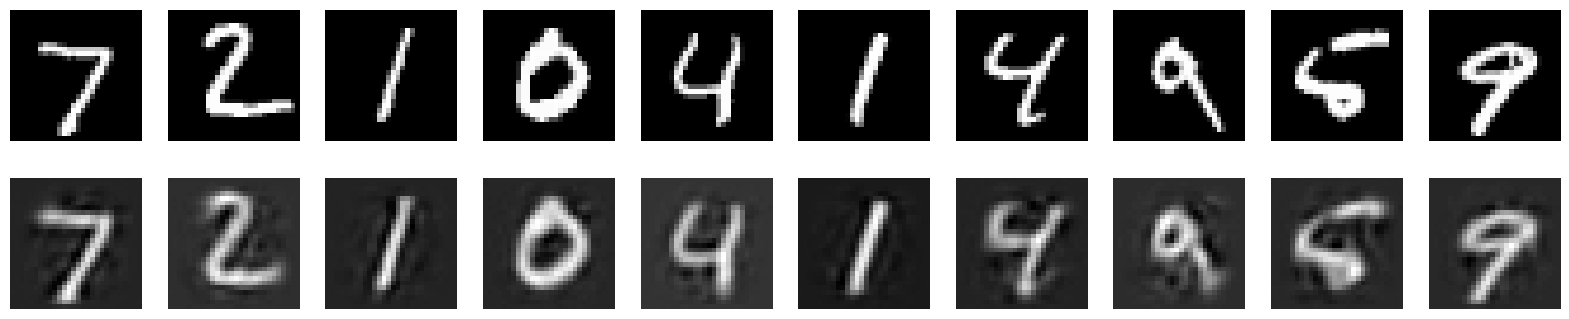

In [ ]:
# Prédiction des données de test
autoencoder.eval()
with torch.no_grad():
    decoded_imgs = autoencoder(x_test.to(device)).cpu().numpy()

n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    ax = plt.subplot(2, n, i+1)
    plt.imshow(x_test[i].numpy().reshape(28, 28), cmap="gray")
    ax.axis("off")

    ax = plt.subplot(2, n, i+1+n)
    plt.imshow(decoded_imgs[i].reshape(28, 28), cmap="gray")
    ax.axis("off")
plt.show()

# Travail à faire


1.   Pour commencer, observez les résultats obtenus avec le code fourni. Les résultats semblent imparfaits, les images reconstruites sont bruitées. Modifiez le code fourni pour transformer le problème de régression en classification binaire (il faut modifier la fonction d'activatio de sortie du réseau et la fonction de coût). Les résultats devraient être bien meilleurs ! Conservez cette formulation (même si elle est non standard) pour la suite.
2.   Avec la dimension d'espace latent qui vous est fournie, on observe une (relativement) faible erreur de reconstruction. Tracez une **courbe** (avec seulement quelques points) qui montre l'évolution de l'**erreur de reconstruction en fonction de la dimension de l'espace latent**. Quelle semble être la dimension minimale de l'espace latent qui permet encore d'observer une reconstruction raisonnable des données (avec le réseau qui vous est fourni) ?
3.   Pour diminuer encore plus la dimension de l'espace latent, il est nécessaire d'augmenter la capacité des réseaux encodeur et décodeur. Cherchez à nouveau la dimension minimale de l'espace latent qui permet d'observer une bonne reconstruction des données, mais en augmentant à l'envi la capacité de votre auto-encodeur.
4.   Écrivez une fonction qui, étant donné deux images de votre espace de test $I_1$ et $I_2$, réalise l'interpolation (avec, par exemple, 10 étapes) entre la représentation latente ($z_1 = $encoder($I_1$) et $z_2 = $encoder($I_2$)) de ces deux données, et génère les images $I_i$ correspondant aux représentations latentes intermédiaires $z_i$. En pseudo python, cela donne :

```python
for i in range(10):
  z_i = z1 + i*(z2-z1)/10
  I_i = decoder(z_i)
```
Testez cette fonction avec un auto-encodeur avec une faible erreur de reconstruction, sur deux données présentant le même chiffre écrit différemment, puis deux chiffres différents.


Vous devriez obtenir un résultat de ce type :    

<img src="https://drive.google.com/uc?id=1GATz2XrXOpnW-S7SzH-kvPzqNIHbaaiB">


5.   Pour finir, le code qui vous est fourni dans la suite permet de télécharger et de préparer une [base de données de visages](http://vis-www.cs.umass.edu/lfw/). ATTENTION : ici les images sont de taille $32\times32$, en couleur, et comportent donc 3 canaux (contrairement aux images de MNIST, qui n'en comptent qu'un). Par analogie avec la question précédente, on pourrait grâce à la représentation latente apprise par un auto-encodeur, réaliser un morphing entre deux visages. Essayez d'abord d'entraîner un auto-encodeur à obtenir une erreur de reconstruction faible. Qu'observe-t-on ?



# Visages

Chargement des données et affichage de quelques échantillons

In [ ]:
import pandas as pd
import tarfile, tqdm, cv2, os
from sklearn.model_selection import train_test_split
import numpy as np

# Télécharger les données de la base "Labelled Faces in the Wild"
!wget -nc https://acarlier.fr/tp/lfw_attributes.txt
!wget -nc https://acarlier.fr/tp/lfw-deepfunneled.tgz
!wget -nc https://acarlier.fr/tp/lfw.tgz

ATTRS_NAME = "lfw_attributes.txt"
IMAGES_NAME = "lfw-deepfunneled.tgz"
RAW_IMAGES_NAME = "lfw.tgz"

def decode_image_from_raw_bytes(raw_bytes):
    img = cv2.imdecode(np.asarray(bytearray(raw_bytes), dtype=np.uint8), 1)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def load_lfw_dataset(use_raw=False, dx=80, dy=80, dimx=45, dimy=45):
    df_attrs = pd.read_csv(ATTRS_NAME, sep="\\t", skiprows=1)
    df_attrs = pd.DataFrame(df_attrs.iloc[:, :-1].values, columns=df_attrs.columns[1:])
    imgs_with_attrs = set(map(tuple, df_attrs[["person", "imagenum"]].values))

    all_photos, photo_ids = [], []
    with tarfile.open(RAW_IMAGES_NAME if use_raw else IMAGES_NAME) as f:
        for m in tqdm.tqdm(f.getmembers()):
            if m.isfile() and m.name.endswith(".jpg"):
                img = decode_image_from_raw_bytes(f.extractfile(m).read())
                img = img[dy:-dy, dx:-dx]
                img = cv2.resize(img, (dimx, dimy))
                fname = os.path.split(m.name)[-1]
                fname_splitted = fname[:-4].replace("_", " ").split()
                person_id = " ".join(fname_splitted[:-1])
                photo_number = int(fname_splitted[-1])
                if (person_id, photo_number) in imgs_with_attrs:
                    all_photos.append(img)
                    photo_ids.append({"person": person_id, "imagenum": photo_number})

    photo_ids = pd.DataFrame(photo_ids)
    all_photos = np.stack(all_photos).astype("uint8")
    all_attrs = photo_ids.merge(df_attrs, on=("person", "imagenum")).drop(["person", "imagenum"], axis=1)
    return all_photos, all_attrs

X, attr = load_lfw_dataset(use_raw=True, dimx=32, dimy=32)
X = X.astype("float32") / 255.
X_train, X_test = train_test_split(X, test_size=0.1, random_state=42)

In [ ]:
import matplotlib.pyplot as plt

n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    ax = plt.subplot(1, n, i+1)
    plt.imshow(X_train[i])
    ax.axis("off")
plt.show()